# Does the conclusion survive a larger cohort?

The per-model notebooks score 128 peptides measured in human serum in vitro. That is a
small sample, so this notebook repeats the comparison on **blood_in_vitro_any_species**, which
triples the peptide count by accepting serum and plasma of any species, still in vitro.

In vivo records stay excluded everywhere: an in vivo half-life measures pharmacokinetic
clearance, not proteolytic stability, so mixing it in would change the question.

If a model were merely under-powered on the primary cohort, its accuracy should improve
here. If the conclusion is about the model, the numbers will not move.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/model_benchmark").is_dir())
sys.path.insert(0, str(ROOT / "src"))

%matplotlib inline
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [2]:
from model_benchmark import report
from model_benchmark.config import COHORTS
from model_benchmark.dataset import cohort_summary, load_cohort
from model_benchmark.pipeline import load_summaries

COHORT_NAMES = ["human_serum_in_vitro", "blood_in_vitro_any_species"]

sizes = []
for name in COHORT_NAMES:
    row = cohort_summary(load_cohort(name))
    row.insert(0, "cohort", name)
    row.insert(1, "description", COHORTS[name]["description"])
    sizes.append(row)
display(pd.concat(sizes, ignore_index=True).style.set_caption("The two evaluation cohorts"))

stored = {}
for name in COHORT_NAMES:
    frame = load_summaries(cohort_name=name)
    if frame.empty:
        print(f"No stored results for {name}")
        continue
    stored[name] = frame
    print(f"{name}: {len(frame)} stored runs")

,cohort,description,peptides,modification_free,records,median_length,min_half_life_s,median_half_life_s,max_half_life_s,log10_range,median_replicate_spread_log10,class_short,class_medium,class_long
0,human_serum_in_vitro,"Human serum, in vitro: the condition published serum predictors target",128,54,153,15.000000,120.000000,4290.000000,421200.000000,3.545307,0.000000,38,55,35
1,blood_in_vitro_any_species,"Serum and plasma of any species, in vitro: largest proteolysis cohort",391,168,563,15.000000,36.000000,4080.000000,843120.000000,4.369587,0.055990,151,132,108


human_serum_in_vitro: 13 stored runs
blood_in_vitro_any_species: 13 stored runs


## Accuracy on both cohorts

Each cohort has its own trivial baseline, because the half-life distribution differs, so
the model error must be read against the baseline of its own cohort.

In [3]:
rows = []
for name, frame in stored.items():
    part = frame.loc[frame.configuration == "as published"][
        ["run", "mae_log10", "baseline_mae_log10", "r2", "spearman_rho", "accuracy",
         "majority_class_accuracy", "interval_hit_rate", "peptides"]
    ].copy()
    part.insert(0, "cohort", name)
    rows.append(part)
combined = pd.concat(rows, ignore_index=True)
display(combined.style.format(precision=3).set_caption("All published configurations, both cohorts"))

for metric in ("spearman_rho", "mae_log10", "accuracy"):
    pivot = combined.pivot_table(index="run", columns="cohort", values=metric)
    display(pivot.style.format(precision=3).set_caption(f"{metric} by cohort"))

,cohort,run,mae_log10,baseline_mae_log10,r2,spearman_rho,accuracy,majority_class_accuracy,interval_hit_rate,peptides
0,human_serum_in_vitro,peptiverse_transformer_chemberta,0.732,0.676,-0.154,-0.085,0.422,0.430,0.180,128
1,human_serum_in_vitro,peptiverse_transformer_esm_log,0.650,0.676,0.004,0.300,0.445,0.430,0.227,128
2,human_serum_in_vitro,peptiverse_transformer_esm_raw,0.656,0.676,0.026,0.216,0.430,0.430,0.203,128
3,human_serum_in_vitro,peptiverse_transformer_peptideclm,0.714,0.676,-0.106,0.144,0.398,0.430,0.148,128
4,human_serum_in_vitro,peptiverse_xgb_chemberta,0.697,0.676,-0.078,0.073,0.422,0.430,0.227,128
5,human_serum_in_vitro,peptiverse_xgb_esm_log,0.865,0.676,-0.659,0.031,0.312,0.430,0.062,128
6,human_serum_in_vitro,peptiverse_xgb_esm_raw,0.881,0.676,-0.739,0.011,0.320,0.430,0.227,128
7,human_serum_in_vitro,peptiverse_xgb_peptideclm,0.680,0.676,-0.031,0.056,0.430,0.430,0.203,128
8,human_serum_in_vitro,plifepred_svm,0.884,0.676,-0.864,0.222,0.320,0.430,0.164,128
9,blood_in_vitro_any_species,peptiverse_transformer_chemberta,0.829,0.806,-0.062,0.029,0.340,0.386,0.166,391


cohort,blood_in_vitro_any_species,human_serum_in_vitro
run,,
peptiverse_transformer_chemberta,0.029,-0.085
peptiverse_transformer_esm_log,0.384,0.300
peptiverse_transformer_esm_raw,0.291,0.216
peptiverse_transformer_peptideclm,-0.065,0.144
peptiverse_xgb_chemberta,-0.124,0.073
peptiverse_xgb_esm_log,0.291,0.031
peptiverse_xgb_esm_raw,0.261,0.011
peptiverse_xgb_peptideclm,0.056,0.056
plifepred_svm,0.167,0.222


cohort,blood_in_vitro_any_species,human_serum_in_vitro
run,,
peptiverse_transformer_chemberta,0.829,0.732
peptiverse_transformer_esm_log,0.741,0.650
peptiverse_transformer_esm_raw,0.780,0.656
peptiverse_transformer_peptideclm,0.845,0.714
peptiverse_xgb_chemberta,0.835,0.697
peptiverse_xgb_esm_log,0.882,0.865
peptiverse_xgb_esm_raw,0.997,0.881
peptiverse_xgb_peptideclm,0.812,0.680
plifepred_svm,0.906,0.884


cohort,blood_in_vitro_any_species,human_serum_in_vitro
run,,
peptiverse_transformer_chemberta,0.340,0.422
peptiverse_transformer_esm_log,0.409,0.445
peptiverse_transformer_esm_raw,0.345,0.430
peptiverse_transformer_peptideclm,0.327,0.398
peptiverse_xgb_chemberta,0.325,0.422
peptiverse_xgb_esm_log,0.407,0.312
peptiverse_xgb_esm_raw,0.299,0.320
peptiverse_xgb_peptideclm,0.338,0.430
plifepred_svm,0.430,0.320


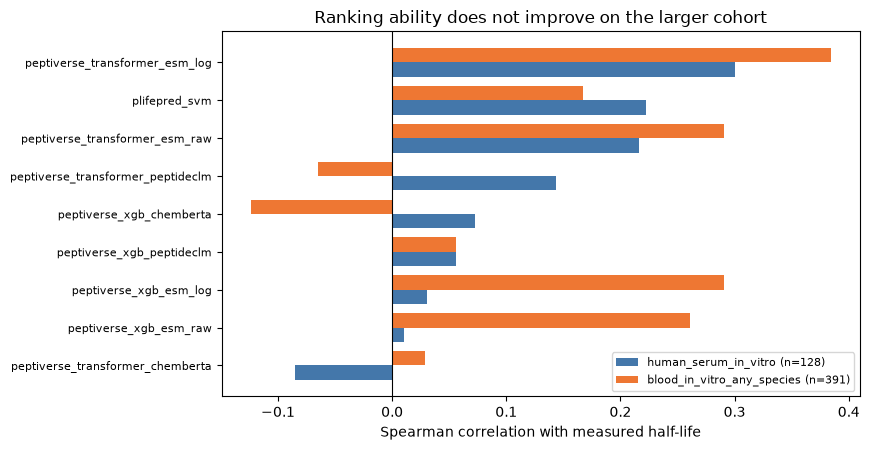

In [4]:
figure, axes = plt.subplots(figsize=(8.8, 4.6))
pivot = combined.pivot_table(index="run", columns="cohort", values="spearman_rho").sort_values(
    COHORT_NAMES[0], ascending=True
)
positions = np.arange(len(pivot))
width = 0.38
for offset, (name, colour) in enumerate(zip(COHORT_NAMES, ("#4477AA", "#EE7733"))):
    if name in pivot:
        axes.barh(positions + (offset - 0.5) * width, pivot[name], height=width,
                  color=colour, label=f"{name} (n={int(combined.loc[combined.cohort == name, 'peptides'].max())})")
axes.axvline(0.0, color="black", linewidth=0.8)
axes.set_yticks(positions, pivot.index, fontsize=8)
axes.set_xlabel("Spearman correlation with measured half-life")
axes.set_title("Ranking ability does not improve on the larger cohort")
axes.legend(fontsize=8)
figure.tight_layout()
display(figure)
plt.close("all")

## Measured single-substitution pairs

The larger cohort also yields more measured parent-variant pairs, which is the part of the
analysis most limited by sample size.

In [5]:
from model_benchmark.sensitivity import empirical_substitution_pairs

for name in COHORT_NAMES:
    pairs = empirical_substitution_pairs(load_cohort(name, aggregate=False))
    resolvable = pairs.loc[pairs.measured_delta_log10.abs() >= 0.1] if not pairs.empty else pairs
    print(f"{name}: {len(pairs)} pairs, {len(resolvable)} with a measured effect of at least 0.1 log10")

rows = []
for name, frame in stored.items():
    part = frame.loc[frame.configuration == "as published"][
        ["run", "pairs_pairs", "pairs_sign_agreement", "pairs_spearman_delta",
         "pairs_predicted_to_measured_effect_ratio", "scan_median_absolute_delta_log10"]
    ].copy()
    part.insert(0, "cohort", name)
    rows.append(part)
display(pd.concat(rows, ignore_index=True).style.format(precision=3)
        .set_caption("Agreement with measured substitutions, both cohorts"))

human_serum_in_vitro: 12 pairs, 9 with a measured effect of at least 0.1 log10
blood_in_vitro_any_species: 49 pairs, 35 with a measured effect of at least 0.1 log10


,cohort,run,pairs_pairs,pairs_sign_agreement,pairs_spearman_delta,pairs_predicted_to_measured_effect_ratio,scan_median_absolute_delta_log10
0,human_serum_in_vitro,peptiverse_transformer_chemberta,9.000,0.556,-0.233,0.199,0.063
1,human_serum_in_vitro,peptiverse_transformer_esm_log,9.000,0.667,0.300,0.137,0.101
2,human_serum_in_vitro,peptiverse_transformer_esm_raw,9.000,0.444,-0.117,0.269,0.101
3,human_serum_in_vitro,peptiverse_transformer_peptideclm,9.000,0.778,0.550,0.076,0.054
4,human_serum_in_vitro,peptiverse_xgb_chemberta,9.000,0.333,0.500,0.107,0.072
5,human_serum_in_vitro,peptiverse_xgb_esm_log,9.000,0.333,-0.067,0.101,0.049
6,human_serum_in_vitro,peptiverse_xgb_esm_raw,9.000,0.444,0.083,0.015,0.012
7,human_serum_in_vitro,peptiverse_xgb_peptideclm,9.000,0.444,0.067,0.064,0.025
8,human_serum_in_vitro,plifepred_svm,9.000,0.222,-0.500,0.006,0.336
9,blood_in_vitro_any_species,peptiverse_transformer_chemberta,35.000,0.571,0.106,0.112,0.048


## Conclusion

Threshold statements over both cohorts.

In [6]:
for name, frame in stored.items():
    published = frame.loc[frame.configuration == "as published"]
    best = published.sort_values("spearman_rho", ascending=False).iloc[0]
    beats_baseline = int((published.mae_log10 < published.baseline_mae_log10).sum())
    beats_chance = int((published.spearman_rho.abs() > 0.2).sum())
    beats_majority = int((published.accuracy > published.majority_class_accuracy).sum())
    print(f"=== {name} ({int(best.peptides)} peptides) ===")
    print(f"  Best model: {best.run}, Spearman {best.spearman_rho:.3f}, MAE {best.mae_log10:.3f} "
          f"against baseline {best.baseline_mae_log10:.3f}")
    print(f"  Runs beating the median baseline in error: {beats_baseline} of {len(published)}")
    print(f"  Runs ordering peptides better than chance: {beats_chance} of {len(published)}")
    print(f"  Runs beating the majority duration class: {beats_majority} of {len(published)}")
    print()

=== human_serum_in_vitro (128 peptides) ===
  Best model: peptiverse_transformer_esm_log, Spearman 0.300, MAE 0.650 against baseline 0.676
  Runs beating the median baseline in error: 2 of 9
  Runs ordering peptides better than chance: 3 of 9
  Runs beating the majority duration class: 1 of 9

=== blood_in_vitro_any_species (391 peptides) ===
  Best model: peptiverse_transformer_esm_log, Spearman 0.384, MAE 0.741 against baseline 0.806
  Runs beating the median baseline in error: 2 of 9
  Runs ordering peptides better than chance: 4 of 9
  Runs beating the majority duration class: 3 of 9

